CMSC320 - Project Checkpoint 2


By: Caroline, Sangeetha, Luis, Ethan

In [2]:
import pandas as pd

df = pd.read_csv('emissions.csv')

df['year'] = df['year'].astype(int)
df['value'] = df['value'].astype(float)
df['sector-name'] = df['sector-name'].str.replace(' carbon dioxide emissions', '', regex=False)

#for i in range(len(df)):
#    row = df.iloc[i]
#   print(f"Year: {row['year']}, State: {row['state-name']}, Sector: {row['sector-name']}, Value: {row['value']}")
df.head(10)


,year,state-name,sector-name,fuel-name,value
0,1970,Alabama,Industrial,Coal,26.721507
1,1970,Alabama,Industrial,Petroleum,3.577779
2,1970,Alabama,Industrial,Natural Gas,8.944097
3,1970,Alabama,Industrial,All Fuels,39.243383
4,1970,Alabama,Total from all sectors,All Fuels,102.646851
5,1970,Alabama,Total from all sectors,Coal,63.266935
6,1970,Alabama,Total from all sectors,Petroleum,23.474612
7,1970,Alabama,Total from all sectors,Natural Gas,15.905305
8,1970,Alabama,Residential,Coal,0.163635
9,1970,Alabama,Residential,Petroleum,1.123947


### Prep stuff

In [ ]:
import matplotlib.pyplot as plt
import piecewise_regression # for piecewise regression model


# get rid of total and all fuels rows since using them would kind of feel like cheating (and they would skew the data for my approach); I'll verify that they match results later.
filtered_df = df[(df["sector-name"] != "Total from all sectors") & (df["fuel-name"] != "All Fuels")].copy()


annual_emissions = (filtered_df.groupby("year")["value"].sum().reset_index().rename(columns={"value": "total_co2"}))

print("\nAnnual Emissions:")
print(annual_emissions.info()) # 52 years of data
#print(annual_emissions.head(10)) 

print("\nFiltered DataFrame:")
#print(filtered_df.info()) # no nulls
print(filtered_df.head(10))





Annual Emissions:
<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   year       52 non-null     int64  
 1   total_co2  52 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 964.0 bytes
None

Filtered DataFrame:
    year state-name     sector-name    fuel-name      value
0   1970    Alabama      Industrial         Coal  26.721507
1   1970    Alabama      Industrial    Petroleum   3.577779
2   1970    Alabama      Industrial  Natural Gas   8.944097
8   1970    Alabama     Residential         Coal   0.163635
9   1970    Alabama     Residential    Petroleum   1.123947
10  1970    Alabama     Residential  Natural Gas   3.049074
12  1970    Alabama      Commercial         Coal   0.128584
13  1970    Alabama      Commercial    Petroleum   0.824345
14  1970    Alabama      Commercial  Natural Gas   1.981782
16  1970    Alabama  Transportation         Coal 

### Linear Regression Lines

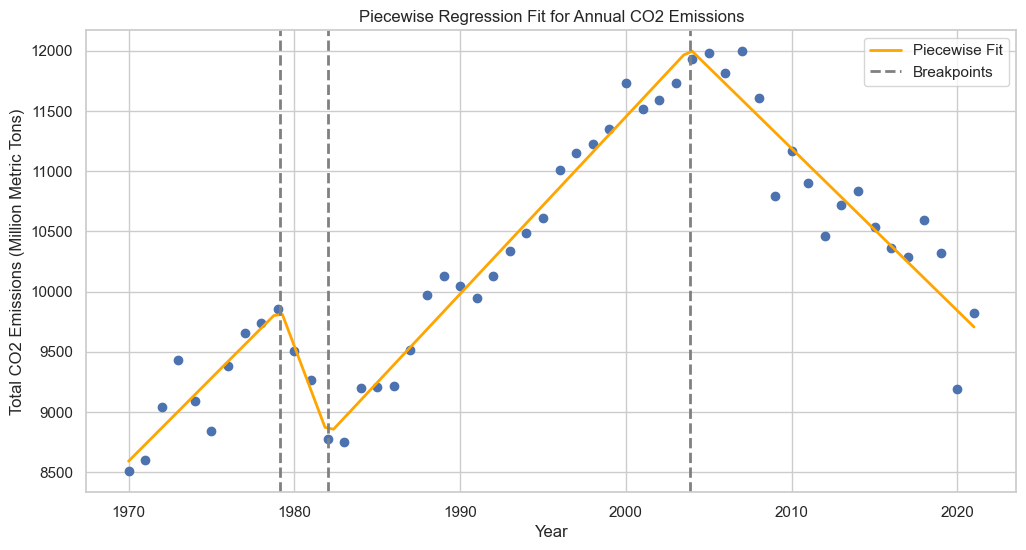

In [43]:

plt.figure(figsize=(12, 6))

# piecewise regression model with three breakpoints
pw_fit_3 = piecewise_regression.Fit(annual_emissions["year"].values, annual_emissions["total_co2"].values, n_breakpoints=3)

# one breakpoint, not a good fit, also kind of lies about the data before 1982
#pw_fit = piecewise_regression.Fit(annual_emissions["year"].values, annual_emissions["total_co2"].values, n_breakpoints=1)
#pw_fit.plot() 

pw_fit_3.plot_data()
pw_fit_3.plot_fit(color='orange', linewidth=2, label='Piecewise Fit')
pw_fit_3.plot_breakpoints(color='grey', linestyle='--', linewidth=2, label='Breakpoints')

# gloriousness
plt.title('Piecewise Regression Fit for Annual CO2 Emissions')
plt.xlabel('Year')
plt.ylabel('Total CO2 Emissions (Million Metric Tons)')
#plt.legend()

# legend had duplicates for breakpoint lines
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles)) # dict to force uniqueness
plt.legend(by_label.values(), by_label.keys())




## Conclusions
Total emissions increase steadily from 1970 thru about 1979, decrease briefly until 1982, increase steadily once again from 1982 thru 2004, and finally trend downwards from 2004 to 2022.

Possible uses for this data are drawing conclusions by cross referencing it with a dataset with temperature or air quality (for example), or by using it to evaluate the effects of policy change, 

